# 1. Etude du dataset

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score,precision_recall_fscore_support
from sklearn.impute import SimpleImputer
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.corpus import stopwords
from collections import Counter
import string
from nltk.corpus import wordnet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv1D, Flatten, MaxPooling1D
import joblib
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

In [3]:
data = pd.read_csv('AI_Human.csv')
data

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0
...,...,...
487230,Tie Face on Mars is really just a big misunder...,0.0
487231,The whole purpose of democracy is to create a ...,0.0
487232,I firmly believe that governments worldwide sh...,1.0
487233,I DFN't agree with this decision because a LFT...,0.0


In [4]:
# Count total entries
total_entries = len(data['generated'])

# Count AI-generated text
ai_generated_count = data['generated'].eq(1.0).sum()

# Count human-generated text
human_generated_count = data['generated'].eq(0.0).sum()

# Print the results
print("Total :", total_entries)
print("Total text by AI :", ai_generated_count)
print("Total text by Human :", human_generated_count)

Total : 487235
Total text by AI : 181438
Total text by Human : 305797


In [5]:
data['generated'].value_counts()

0.0    305797
1.0    181438
Name: generated, dtype: int64

In [6]:
percentage_ai = (ai_generated_count / total_entries) * 100
percentage_human = (human_generated_count / total_entries) * 100

print("Percentage of text by AI:", round(percentage_ai, 2), "%")
print("Percentage of text by Human:", round(percentage_human, 2), "%")

Percentage of text by AI: 37.24 %
Percentage of text by Human: 62.76 %


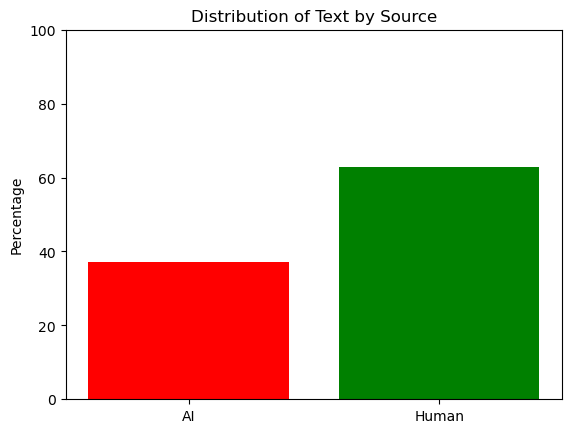

In [7]:
categories = ['AI', 'Human']
percentages = [percentage_ai, percentage_human]

# Create bar chart
plt.bar(categories, percentages, color=['red', 'green'])
plt.ylabel('Percentage')
plt.title('Distribution of Text by Source')
plt.ylim(0, 100)
plt.show()

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 487235 entries, 0 to 487234
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   text       487235 non-null  object 
 1   generated  487235 non-null  float64
dtypes: float64(1), object(1)
memory usage: 7.4+ MB


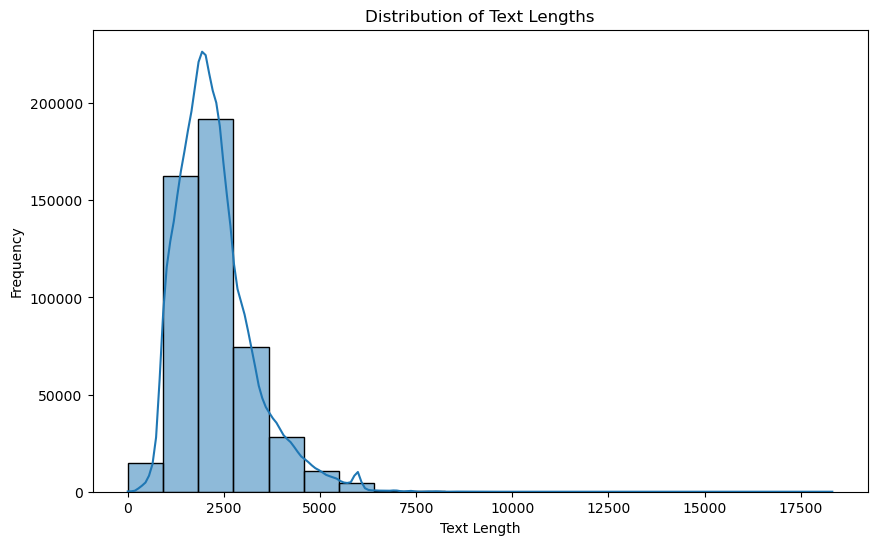

In [9]:
data['text_length'] = data['text'].apply(len)
plt.figure(figsize=(10, 6))
sns.histplot(data['text_length'], bins=20, kde=True)
plt.title("Distribution of Text Lengths")
plt.xlabel("Text Length")
plt.ylabel("Frequency")
plt.show()

# 2.creation et etude du jeu d'entrainement

In [10]:
df=data.copy()

In [11]:
df0_text = df[df['generated'] == 0].copy()
df1_ai = df[df['generated'] == 1].copy()

df0_text= df0_text[:130000]
df1_ai= df1_ai[:130000]

df = pd.concat([df0_text,df1_ai], ignore_index=True)
df

,text,generated,text_length
0,Cars. Cars have been around since they became ...,0.0,3289
1,Transportation is a large necessity in most co...,0.0,2738
2,"""America's love affair with it's vehicles seem...",0.0,4428
3,How often do you ride in a car? Do you drive a...,0.0,4013
4,Cars are a wonderful thing. They are perhaps o...,0.0,4698
...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,2046
259996,Having a positive attitude is an important fac...,1.0,1235
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,4235
259998,"As an eighth grade student, I am constantly th...",1.0,2083


In [12]:
nltk.download('vader_lexicon')
nltk.download('punkt')

[nltk_data] Downloading package vader_lexicon to C:\Users\Bachir
[nltk_data]     Traore\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\Bachir
[nltk_data]     Traore\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [2]:


# Charger le modèle en anglais de spaCy
nlp = spacy.load('en_core_web_sm')

# Function to count the length of each text and perform sentiment analysis
def analyze_text(text):
    tokens = word_tokenize(text.lower())
    tokens = [token for token in tokens if token not in stop_words and token not in linking_words]
    tokens = [token for token in tokens if token.isalpha()]
    # Sentiment analysis
    sentiment_scores = sid.polarity_scores(text)
    return len(tokens), sentiment_scores['compound']


#compter le nombre de pnctuations
def count_punctuation_marks(text):
    punctuation_count = sum(1 for char in text if char in string.punctuation)
    return punctuation_count


#compter le nombre de mots de liaison
def count_linking_words(text):
    linking_words_count = sum(1 for word in word_tokenize(text.lower()) if word in linking_words)
    return linking_words_count

# Function to tokenize text and remove stopwords
def tokenize_text(text):
    tokens = word_tokenize(text.lower())
    stop_words = set(stopwords.words('english'))
    return [token for token in tokens if token.isalpha() and token not in stop_words]

# Function to create binary features for the top words
def create_word_features(text):
    tokens = tokenize_text(text)
    return [1 if word in tokens else 0 for word in top_words]

#fonction pour calculer la longueur d'un text
def lengthText(text):
    tokens = word_tokenize(text.lower())
    return len(tokens)

# Function to calculate percentage of synonyms in a text
def calculate_punctuation_count(text):
    tokens = word_tokenize(text)
    if len(tokens) > 0:
        return count_punctuation_marks(text) / len(tokens) * 100
    else:
        #pour eviter le zerodivisionerror
        return 0

# Function to calculate percentage of synonyms in a text
def calculate_linking_words_count(text):
    tokens = word_tokenize(text)
    if len(tokens) > 0:
        return count_linking_words(text) / len(tokens) * 100
    else:
        return 0
    
# Fonction pour effectuer l'analyse lexicale et syntaxique d'un texte et calculer le pourcentage de fiabilité lexicale
def analyze_text_and_compute_lexical_reliability(text):
    # Traiter le texte avec spaCy
    doc = nlp(text)
    
    # Initialiser le compteur pour les tokens corrects
    correct_tokens = 0
    
    # Parcourir chaque token dans le texte
    for token in doc:
        # Vérifier si le token est correct (non-stopword et non-punctuation)
        if not token.is_stop and not token.is_punct:
            # Incrémenter le compteur des tokens corrects
            correct_tokens += 1
    
    # Calculer le pourcentage de fiabilité lexicale
    lexical_reliability_percentage = (correct_tokens / len(doc)) * 100
    
    return lexical_reliability_percentage

In [14]:
porter = PorterStemmer()
stop_words = set(stopwords.words('english'))
linking_words = {'to', 'the', 'and', 'of', 'in', 'on', 'for', 'with', 'at', 'a', 'an'}

# Initialize sentiment analyzer
sid = SentimentIntensityAnalyzer()

# Function to count the length of each text and perform sentiment analysis
def analyze_text(text):
    tokens = word_tokenize(text.lower())
    tokens = [token for token in tokens if token not in stop_words and token not in linking_words]
    tokens = [token for token in tokens if token.isalpha()]
    # Sentiment analysis
    sentiment_scores = sid.polarity_scores(text)
    return len(tokens), sentiment_scores['compound']



df0_text = df[df['generated'] == 0].copy()
df1_ai = df[df['generated'] == 1].copy()


df0_text[['text_length', 'sentiment_score']] = df0_text['text'].apply(lambda x: pd.Series(analyze_text(x)))
df1_ai[['text_length', 'sentiment_score']] = df0_text['text'].apply(lambda x: pd.Series(analyze_text(x)))


In [15]:
df0_text['punctuation_count'] = df0_text['text'].apply(count_punctuation_marks)
df1_ai['punctuation_count'] = df1_ai['text'].apply(count_punctuation_marks)

df0_text['linking_words_count'] = df0_text['text'].apply(count_linking_words)
df1_ai['linking_words_count'] = df1_ai['text'].apply(count_linking_words)

df = pd.concat([df0_text,df1_ai], ignore_index=False)
df

,text,generated,text_length,sentiment_score,punctuation_count,linking_words_count
0,Cars. Cars have been around since they became ...,0.0,315.0,0.9643,75,131
1,Transportation is a large necessity in most co...,0.0,257.0,-0.2426,64,108
2,"""America's love affair with it's vehicles seem...",0.0,408.0,0.9909,101,162
3,How often do you ride in a car? Do you drive a...,0.0,364.0,0.9902,124,133
4,Cars are a wonderful thing. They are perhaps o...,0.0,462.0,-0.9005,110,155
...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,NaN,NaN,43,74
259996,Having a positive attitude is an important fac...,1.0,NaN,NaN,20,54
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,NaN,NaN,83,162
259998,"As an eighth grade student, I am constantly th...",1.0,NaN,NaN,39,66


In [ ]:
# Calculate the mean punctuation count and linking words count for the first 1500000 texts
first_130000_mean_punctuation = df.iloc[:130000]['punctuation_count'].mean()
first_130000_mean_linking_words = df.iloc[:130000]['linking_words_count'].mean()

# Calculate the mean punctuation count and linking words count for the next 150000 texts
next_130000_punctuation = df.iloc[130000:260000]['punctuation_count'].mean()
next_130000_mean_linking_words = df.iloc[130000:260000]['linking_words_count'].mean()


plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.bar(['text by human', 'text by ai'], [first_130000_mean_punctuation, next_130000_mean_punctuation ], color=['blue', 'orange'])
plt.title('Mean Punctuation Count')
plt.ylabel('Count')


plt.subplot(2, 1, 2)
plt.bar(['text by human', 'text by ai'], [first_130000_mean_linking_words, next_130000_mean_linking_words], color=['blue', 'orange'])
plt.title('Mean Linking Words Count')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [16]:
# Make a duplicate of the DataFrame
df_copy = df.copy()

# Remove the columns text_length and sentiment_score because they didnt help for our model
df_copy.drop(['text_length', 'sentiment_score'], axis=1, inplace=True)
df_copy.fillna(0, inplace=True)

# Verify the changes
df_copy

,text,generated,punctuation_count,linking_words_count
0,Cars. Cars have been around since they became ...,0.0,75,131
1,Transportation is a large necessity in most co...,0.0,64,108
2,"""America's love affair with it's vehicles seem...",0.0,101,162
3,How often do you ride in a car? Do you drive a...,0.0,124,133
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155
...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74
259996,Having a positive attitude is an important fac...,1.0,20,54
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162
259998,"As an eighth grade student, I am constantly th...",1.0,39,66


In [17]:
# Tokenize all texts and count word occurrences
all_words = [word for text in df_copy['text'] for word in tokenize_text(text)]
word_counts = Counter(all_words)

# Select the top 500 most common words as features
top_words = [word for word, _ in word_counts.most_common(500)]

df_copy['length_text'] = df_copy['text'].apply(lengthText)
# Create binary features for the top words in each text
df_copy['word_features'] = df_copy['text'].apply(create_word_features)
df_copy

,text,generated,punctuation_count,linking_words_count,length_text,word_features
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ..."
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ..."
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ..."
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ..."
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ..."
...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ..."
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ..."
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ..."


In [18]:
df_copy['punctuation_count_percentage'] = df_copy['text'].apply(calculate_punctuation_count)

# Add a column to df0_text for synonym percentage
df_copy['linking_words_percentage'] = df_copy['text'].apply(calculate_linking_words_count)


df_copy

,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872
...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317


In [3]:
df_copy2 = pd.read_csv('finaldataframe.csv')
df_copy2

,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872
...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317


In [4]:


from nltk.util import ngrams
from nltk.tokenize import word_tokenize

def generate_ngrams(text, n, tokenizer=word_tokenize):
    """
    Fonction pour générer les n-grammes d'un texte.

    Args:
        text: Le texte à analyser.
        n: La taille des n-grammes à générer.
        tokenizer: La fonction de tokenisation à utiliser (par défaut: word_tokenize de NLTK).

    Returns:
        Une liste de n-grammes.
    """
    tokens = tokenizer(text)
    ngrams_list = list(ngrams(tokens, n))
    return [' '.join(gram) for gram in ngrams_list]

# Définir la taille des n-grammes
n = 2

# Créer une nouvelle colonne "ngramme" en utilisant la fonction generate_ngrams
df_copy2['ngramme'] = df_copy2['text'].apply(lambda text: generate_ngrams(text, n))

# Afficher le dataframe
df_copy2

,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage,ngramme
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815,"[Cars ., . Cars, Cars have, have been, been ar..."
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319,"[Transportation is, is a, a large, large neces..."
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905,"[`` America, America 's, 's love, love affair,..."
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739,"[How often, often do, do you, you ride, ride i..."
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872,"[Cars are, are a, a wonderful, wonderful thing..."
...,...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349,"[The statement, statement ``, `` You, You neve..."
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805,"[Having a, a positive, positive attitude, atti..."
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816,"[] Dear, Dear [, [ Senator, Senator 's, 's Nam..."
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317,"[As an, an eighth, eighth grade, grade student..."


In [5]:
import spacy
import pandas as pd

# Charger le modèle en anglais de spaCy
nlp = spacy.load('en_core_web_sm')

# Fonction pour effectuer l'analyse lexicale et syntaxique d'un texte et calculer le pourcentage de fiabilité lexicale
def analyze_text_and_compute_lexical_reliability(text):
    # Traiter le texte avec spaCy
    doc = nlp(text)
    
    # Initialiser le compteur pour les tokens corrects
    correct_tokens = 0
    
    # Parcourir chaque token dans le texte
    for token in doc:
        # Vérifier si le token est correct (non-stopword et non-punctuation)
        if not token.is_stop and not token.is_punct:
            # Incrémenter le compteur des tokens corrects
            correct_tokens += 1
    
    # Calculer le pourcentage de fiabilité lexicale
    lexical_reliability_percentage = (correct_tokens / len(doc)) * 100
    
    return lexical_reliability_percentage

# Appliquer l'analyse lexicale et syntaxique à tous les textes de df_copy2['text']
df_copy2['lexical_reliability_percentage'] = df_copy2['text'].apply(analyze_text_and_compute_lexical_reliability)

# Afficher les cinq premières lignes du dataframe avec la nouvelle colonne ajoutée
df_copy2


,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage,ngramme,lexical_reliability_percentage
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815,"[Cars ., . Cars, Cars have, have been, been ar...",45.151515
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319,"[Transportation is, is a, a large, large neces...",43.396226
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905,"[`` America, America 's, 's love, love affair,...",42.198582
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739,"[How often, often do, do you, you ride, ride i...",39.975248
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872,"[Cars are, are a, a wonderful, wonderful thing...",41.025641
...,...,...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349,"[The statement, statement ``, `` You, You neve...",36.255924
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805,"[Having a, a positive, positive attitude, atti...",45.175439
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816,"[] Dear, Dear [, [ Senator, Senator 's, 's Nam...",49.731903
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317,"[As an, an eighth, eighth grade, grade student...",43.080940


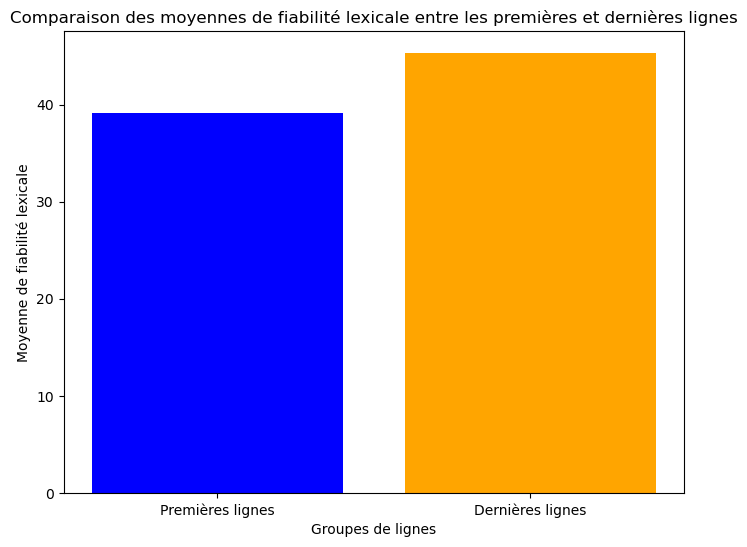

In [6]:
import matplotlib.pyplot as plt

# Sélectionner les 130000 premières lignes du dataframe
first_130000 = df_copy2.head(130000)

# Sélectionner les 130000 dernières lignes du dataframe
last_130000 = df_copy2.tail(130000)

# Calculer la moyenne de fiabilité lexicale pour les 130000 premières lignes
mean_lexical_reliability_first = first_130000['lexical_reliability_percentage'].mean()

# Calculer la moyenne de fiabilité lexicale pour les 130000 dernières lignes
mean_lexical_reliability_last = last_130000['lexical_reliability_percentage'].mean()

# Créer un histogramme comparant les moyennes de fiabilité lexicale
plt.figure(figsize=(8, 6))
plt.bar(['Premières lignes', 'Dernières lignes'], [mean_lexical_reliability_first, mean_lexical_reliability_last], color=['blue', 'orange'])
plt.xlabel('Groupes de lignes')
plt.ylabel('Moyenne de fiabilité lexicale')
plt.title('Comparaison des moyennes de fiabilité lexicale entre les premières et dernières lignes')
plt.show()


In [7]:
df_copy2

,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage,ngramme,lexical_reliability_percentage
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815,"[Cars ., . Cars, Cars have, have been, been ar...",45.151515
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319,"[Transportation is, is a, a large, large neces...",43.396226
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905,"[`` America, America 's, 's love, love affair,...",42.198582
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739,"[How often, often do, do you, you ride, ride i...",39.975248
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872,"[Cars are, are a, a wonderful, wonderful thing...",41.025641
...,...,...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349,"[The statement, statement ``, `` You, You neve...",36.255924
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805,"[Having a, a positive, positive attitude, atti...",45.175439
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816,"[] Dear, Dear [, [ Senator, Senator 's, 's Nam...",49.731903
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317,"[As an, an eighth, eighth grade, grade student...",43.080940


In [ ]:
csv_file_path2 = 'final_dataframef21.csv'

df_copy2.to_csv(csv_file_path2, index=False)

# 3.Entrainement du modele

In [14]:
df_copy = pd.read_csv('final_dataframef21.csv')
df_copy

,text,generated,punctuation_count,linking_words_count,length_text,word_features,punctuation_count_percentage,linking_words_percentage,ngramme,lexical_reliability_percentage
0,Cars. Cars have been around since they became ...,0.0,75,131,657,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, ...",11.398176,19.908815,"['Cars .', '. Cars', 'Cars have', 'have been',...",45.151515
1,Transportation is a large necessity in most co...,0.0,64,108,526,"[0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, ...",12.167300,20.532319,"['Transportation is', 'is a', 'a large', 'larg...",43.396226
2,"""America's love affair with it's vehicles seem...",0.0,101,162,842,"[0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, ...",11.995249,19.239905,"['`` America', ""America 's"", ""'s love"", 'love ...",42.198582
3,How often do you ride in a car? Do you drive a...,0.0,124,133,805,"[0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, ...",15.403727,16.521739,"['How often', 'often do', 'do you', 'you ride'...",39.975248
4,Cars are a wonderful thing. They are perhaps o...,0.0,110,155,967,"[0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, ...",11.351909,15.995872,"['Cars are', 'are a', 'a wonderful', 'wonderfu...",41.025641
...,...,...,...,...,...,...,...,...,...,...
259995,"The statement ""You never to be idle, because ...",1.0,43,74,418,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, ...",10.287081,17.703349,"['The statement', 'statement ``', '`` You', 'Y...",36.255924
259996,Having a positive attitude is an important fac...,1.0,20,54,226,"[0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",8.849558,23.893805,"['Having a', 'a positive', 'positive attitude'...",45.175439
259997,"]\n\nDear [Senator's Name],\n\nI am writing to...",1.0,83,162,735,"[0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, ...",11.292517,22.040816,"['] Dear', 'Dear [', '[ Senator', ""Senator 's""...",49.731903
259998,"As an eighth grade student, I am constantly th...",1.0,39,66,378,"[0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",10.317460,17.460317,"['As an', 'an eighth', 'eighth grade', 'grade ...",43.080940


In [ ]:
# Tokenize all texts and count word occurrences
all_words = [word for text in df_copy['text'] for word in tokenize_text(text)]
word_counts = Counter(all_words)

# Select the top 500 most common words as features
top_words = [word for word, _ in word_counts.most_common(500)]


# Define features (word features, punctuation count, count of synonyms) and target variable
X = pd.DataFrame(df_copy['word_features'], columns=top_words)
X['punctuation_count_percentage'] = df_copy['punctuation_count_percentage']
X['linking_words_percentage'] = df_copy['linking_words_percentage']
X['length_text'] = df_copy['length_text']
X['lexical_reliability_percentage'] = df_copy['lexical_reliability_percentage']
y = df_copy['generated']

In [3]:
X = pd.read_csv('X.csv')
y = pd.read_csv('y.csv')

In [4]:


# Répartition des données en données d'entraînement (60%), de validation (20%) et de test (20%)
A_train, A_temp, v_train, v_temp = train_test_split(X, y, test_size=0.45, random_state=42)
A_valid, A_test, v_valid, v_test = train_test_split(A_temp, v_temp, test_size=0.5, random_state=42)

# Afficher les tailles des ensembles de données
print("Taille de l'ensemble d'entraînement :", A_train.shape[0])
print("Taille de l'ensemble de validation :", A_valid.shape[0])
print("Taille de l'ensemble de test :", A_test.shape[0])

Taille de l'ensemble d'entraînement : 143000
Taille de l'ensemble de validation : 58500
Taille de l'ensemble de test : 58500


In [10]:
from sklearn.linear_model import LogisticRegressionCV

# Initialize SimpleImputer, Fit and transform the imputer on the feature matrix X, Initialize and train the Logistic Regression classifier
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_train_imputed = imputer.fit_transform(A_train)
X_test_imputed = imputer.transform(A_test)
X_valid_imputed = imputer.transform(A_valid)

# Créer un objet LogisticRegressionCV
log_reg_cv2 = LogisticRegressionCV(Cs=10, cv=5, max_iter=3000, random_state=42)

# Adapter le modèle sur les données d'entraînement
log_reg_cv2.fit(X_train_imputed, v_train)

# Prédire les classes sur l'ensemble de validation
v_valid_pred = log_reg_cv2.predict(X_valid_imputed )

# Calculer l'exactitude sur l'ensemble de validation
accuracy_valid = accuracy_score(v_valid, v_valid_pred)
print("Accuracy on validation set:", accuracy_valid)

# Prédire les classes sur l'ensemble de test
v_test_pred = log_reg_cv2.predict(X_test_imputed)

# Calculer l'exactitude sur l'ensemble de test
accuracy_test = accuracy_score(v_test, v_test_pred)
print("Accuracy on test set:", accuracy_test)

# Afficher les meilleurs paramètres de régularisation sélectionnés par la validation croisée
print("Best regularization parameter (C):", log_reg_cv2.C_)

Accuracy on validation set: 0.7655555555555555
Accuracy on test set: 0.7655726495726496
Best regularization parameter (C): [21.5443469]


In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Calculer les scores de décision sur l'ensemble de validation
decision_scores = log_reg_cv2.decision_function(X_valid_imputed)

# Calculer la précision, le rappel et les seuils
precision, recall, thresholds = precision_recall_curve(v_valid, decision_scores)

# Tracer la courbe Rappel-Précision
plt.plot(recall, precision, marker='.')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbe Rappel-Précision')
plt.show()

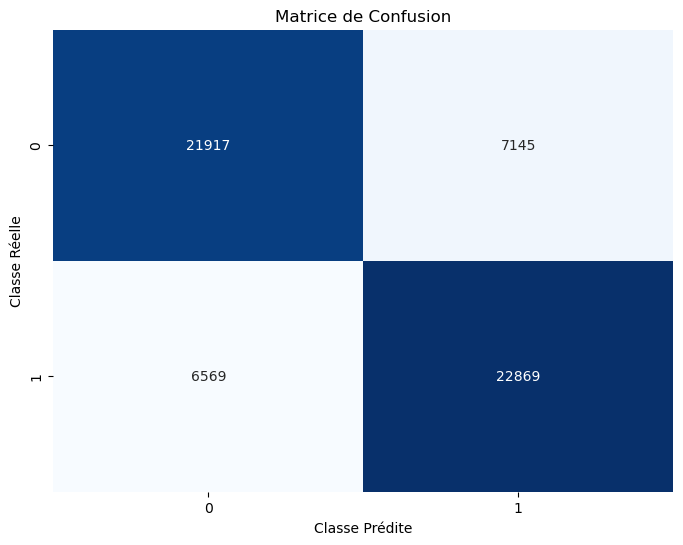

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Calculer la matrice de confusion sur l'ensemble de test
conf_matrix = confusion_matrix(v_test, v_test_pred)

# Tracer la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Classe Prédite')
plt.ylabel('Classe Réelle')
plt.title('Matrice de Confusion')
plt.show()

In [24]:
import joblib

# Définir le chemin de fichier où vous souhaitez enregistrer votre modèle
file_path = "logistic_regression_model.pkl"

# Enregistrer le modèle sur le disque
joblib.dump(log_reg_cv2, file_path)

['logistic_regression_model.pkl']

In [29]:


features = df_copy[['punctuation_count_percentage', 'linking_words_percentage','lexical_reliability_percentage']]
#On vectorise les donnees textuelles
vectorizer2 = TfidfVectorizer(max_features=500)
X_v = vectorizer2.fit_transform(df_copy['text'])
X_featured = np.concatenate((features, X_v.toarray()), axis=1)

v = df_copy['generated']

# Répartition des données en données d'entraînement (60%), de validation (20%) et de test (20%)
A_train, A_temp, v_train, v_temp = train_test_split(X_featured, v, test_size=0.45, random_state=42)
A_valid, A_test, v_valid, v_test = train_test_split(A_temp, v_temp, test_size=0.5, random_state=42)

# Afficher les tailles des ensembles de données
print("Taille de l'ensemble d'entraînement :", A_train.shape[0])
print("Taille de l'ensemble de validation :", A_valid.shape[0])
print("Taille de l'ensemble de test :", A_test.shape[0])

KeyboardInterrupt: 

In [ ]:
from sklearn.linear_model import LogisticRegressionCV

# Créer un objet LogisticRegressionCV
log_reg_cv3 = LogisticRegressionCV(Cs=10, cv=5, max_iter=3000, random_state=42)

# Adapter le modèle sur les données d'entraînement
log_reg_cv3.fit(A_train, v_train)

# Prédire les classes sur l'ensemble de validation
v_valid_pred = log_reg_cv3.predict(A_valid)

# Calculer l'exactitude sur l'ensemble de validation
accuracy_valid = accuracy_score(v_valid, v_valid_pred)
print("Accuracy on validation set:", accuracy_valid)

# Prédire les classes sur l'ensemble de test
v_test_pred = log_reg_cv3.predict(A_test)

# Calculer l'exactitude sur l'ensemble de test
accuracy_test = accuracy_score(v_test, v_test_pred)
print("Accuracy on test set:", accuracy_test)

# Afficher les meilleurs paramètres de régularisation sélectionnés par la validation croisée
print("Best regularization parameter (C):", log_reg_cv3.C_)


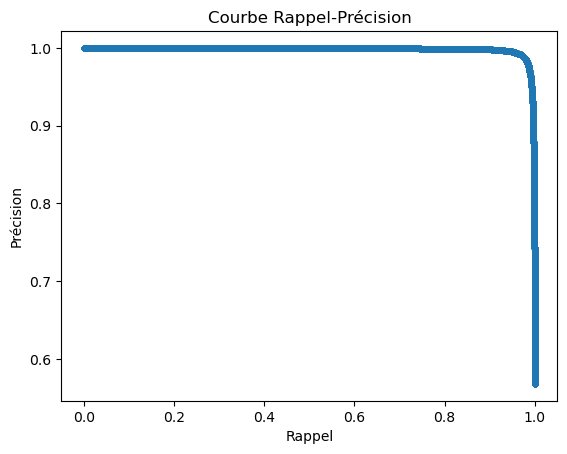

In [20]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Calculer les scores de décision sur l'ensemble de validation
decision_scores = log_reg_cv3.decision_function(A_valid)

# Calculer la précision, le rappel et les seuils
precision, recall, thresholds = precision_recall_curve(v_valid, decision_scores)

# Tracer la courbe Rappel-Précision
plt.plot(recall, precision, marker='.')
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbe Rappel-Précision')
plt.show()


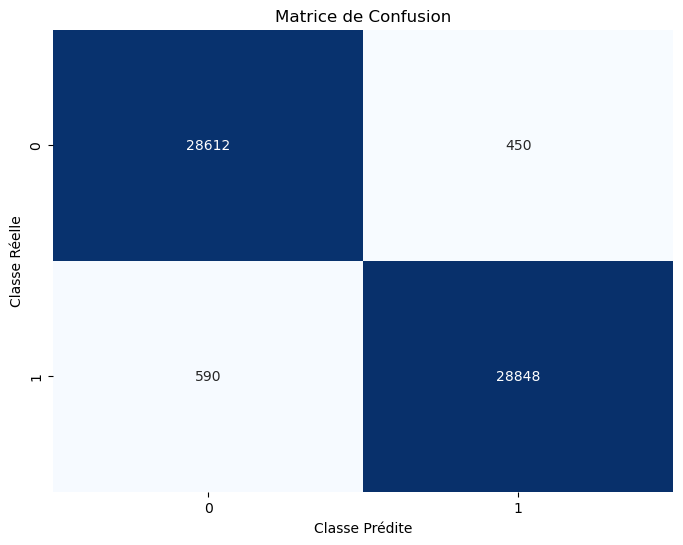

In [21]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Calculer la matrice de confusion sur l'ensemble de test
conf_matrix = confusion_matrix(v_test, v_test_pred)

# Tracer la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Classe Prédite')
plt.ylabel('Classe Réelle')
plt.title('Matrice de Confusion')
plt.show()


In [25]:
# Définir le chemin de fichier où vous souhaitez enregistrer votre modèle
file_path2 = "logistic_regression_model2.pkl"

# Enregistrer le modèle sur le disque
joblib.dump(log_reg_cv3, file_path2)

['logistic_regression_model2.pkl']

# 4.Test de generalisation du modele

In [3]:
df = pd.read_csv('AI_Human.csv').copy()
df_copy = pd.read_csv('final_dataframef21.csv')

In [4]:
# Charger les modèle à partir des fichiers
loaded_model = joblib.load("logistic_regression_model.pkl")
loaded_model2 = joblib.load("logistic_regression_model2.pkl")

In [5]:
df0_text = df[df['generated'] == 0].copy()
df1_ai = df[df['generated'] == 1].copy()

df0_text= df0_text[130000:]
df1_ai= df1_ai[130000:]

generalisation = pd.concat([df0_text,df1_ai], ignore_index=True)
generalisation

,text,generated
0,"So, you have read the article Unmasking the Fa...",0.0
1,I am for the value of using this technology to...,0.0
2,"In the world we live in, everyone has a cell p...",0.0
3,Could you imagine a life without a car? Well i...,0.0
4,Driverless Cars Are Not Good!\n\nDriverless ca...,0.0
...,...,...
227230,I agree that online or video Conferencing dis...,1.0
227231,The Benefits of Limiting Car Usage \n\nMany ci...,1.0
227232,"As an eighth grade student, I believe that att...",1.0
227233,It is a common belief that having a broad know...,1.0


In [8]:

vectorizer2 = TfidfVectorizer(max_features=500)
X_v = vectorizer2.fit_transform(df_copy['text'])
stop_words = set(stopwords.words('english'))
linking_words = {'to', 'the', 'and', 'of', 'in', 'on', 'for', 'with', 'at', 'a', 'an'}

def preprocess_text_for_prediction(text):

    # Analyse lexicale et syntaxique du texte avec spaCy pour calculer la fiabilité lexicale
    lexical_reliability_percentage = analyze_text_and_compute_lexical_reliability(text)
    
    # Compter le nombre de ponctuations et de mots de liaison
    punctuation_percentage = calculate_punctuation_count(text)
    linking_words_percentage = calculate_linking_words_count(text)

    # Vectorisation du texte avec TfidfVectorizer
    text_vectorized = vectorizer2.transform([text])

    # Concaténation de toutes les fonctionnalités
    features = np.array([
        [punctuation_percentage, linking_words_percentage, lexical_reliability_percentage]
    ])

    # Concaténer les vecteurs de texte avec les autres fonctionnalités
    features = np.concatenate((features, text_vectorized.toarray()), axis=1)

    # Retourne les données prêtes pour la prédiction
    return features


In [9]:
# Utilisation de la fonction sur un exemple de texte
example_text = "C'est un exemple de texte pour tester la fonction."
processed_data = preprocess_text_for_prediction(example_text)

# Prédiction avec le modèle
predicted_class = loaded_model2.predict(processed_data)
print("Predicted class:", predicted_class)

Predicted class: [1.]


In [10]:
# Initialiser les compteurs
total_texts = 0
predicted_1 = 0
predicted_0 = 0

# Parcourir tous les textes de la colonne 'text' de df1_ai
for text in df1_ai['text']:
    # Prétraiter le texte pour la prédiction
    processed_data = preprocess_text_for_prediction(text)
    
    # Prédire la classe avec le modèle chargé
    predicted_class = loaded_model2.predict(processed_data)
    
    # Incrémenter le compteur total de textes
    total_texts += 1
    
    # Vérifier la prédiction et incrémenter les compteurs appropriés
    if predicted_class == 1:
        predicted_1 += 1
    else:
        predicted_0 += 1

# Afficher les résultats
print("Nombre total de textes prédits :", total_texts)
print("Nombre de textes prédits comme 1 :", predicted_1)
print("Nombre de textes prédits comme 0 :", predicted_0)


Nombre total de textes prédits : 51438
Nombre de textes prédits comme 1 : 50367
Nombre de textes prédits comme 0 : 1071


In [11]:
# Initialiser les compteurs
total_texts = 0
predicted_1 = 0
predicted_0 = 0

# Parcourir tous les textes de la colonne 'text' de df0_text
for text in df0_text['text']:
    # Prétraiter le texte pour la prédiction
    processed_data = preprocess_text_for_prediction(text)
    
    # Prédire la classe avec le modèle chargé
    predicted_class = loaded_model2.predict(processed_data)
    
    # Incrémenter le compteur total de textes
    total_texts += 1
    
    # Vérifier la prédiction et incrémenter les compteurs appropriés
    if predicted_class == 1:
        predicted_1 += 1
    else:
        predicted_0 += 1

# Afficher les résultats
print("Nombre total de textes prédits :", total_texts)
print("Nombre de textes prédits comme 1 :", predicted_1)
print("Nombre de textes prédits comme 0 :", predicted_0)


Nombre total de textes prédits : 175797
Nombre de textes prédits comme 1 : 3622
Nombre de textes prédits comme 0 : 172175
